In [27]:
from langgraph.graph import StateGraph,MessagesState,START,END
from langchain_groq import ChatGroq

from langchain_core.messages import HumanMessage,AIMessage
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import RemoveMessage
from dotenv import load_dotenv
load_dotenv()
import os 
os.environ['LANGCHAIN_PROJECT']="summarise_State"

In [28]:
model = ChatGroq( model="openai/gpt-oss-20b",
    temperature=0.7)

In [29]:
class graph_State(MessagesState):
    summary:str

In [30]:


def chat_node(state:graph_State):
    
    summary = state['summary']
    messages = []
    if summary:
        messages.append({"summary":summary})

    messages.extend(state['messages'])
    res = model.invoke(messages)

    return {"messages":[res.content]}

def summarise(state:graph_State):
    summary = state['summary']

    if summary:
        prompt = f"this is the existing summary-{summary} , extend it using the conversation above.-{state['messages']}"
    else:
        prompt = f"summarise this whole conversation present above.-{state['messages']}"

    res = model.invoke(prompt)

    if len(state['messages'])>6:
        to_delete = state['messages'][:-2]
        return {
            "summary":res.content,
            "messages":[RemoveMessage(id=m.id) for m in to_delete if m is not None]
        }
    return {
        "summary":res.content,
        "messages":[state['messages']]
    }

In [31]:
checkpointer = InMemorySaver()

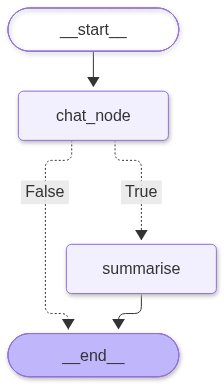

In [32]:
graph = StateGraph(graph_State)

graph.add_node("chat_node",chat_node)
graph.add_node("summarise",summarise)

def should_summarise(state: graph_State):
    if len(state["messages"]) > 6:
        return True
    return False

graph.add_edge(START,"chat_node")
graph.add_conditional_edges(
    "chat_node",
    should_summarise,
    {
        True: "summarise",
        False: END,
    },
)
graph.add_edge("summarise", END)

final_graph = graph.compile(checkpointer=checkpointer)

final_graph

In [37]:
config = {"configurable":{"thread_id":"thread-1"}}
def show_state():
    snapshot = final_graph.get_state(config)
    values = snapshot.values

    print("\n--- STATE ---")
    print("summary:", values.get("summary", ""))
    print("num_messages:", len(values.get("messages", [])))
    print("messages:")

    for message in values.get("messages", []):
        print(
            "-",
            type(message).__name__,
            ":",
            message.content[:80],
        )

In [42]:

show_state()
res = final_graph.invoke(
    {
        "messages": [
            HumanMessage(content="What is RDR2?")
        ],
        "summary": ""
    },
    config=config
)

res["messages"]


--- STATE ---
summary: **Conversation Summary**

- **User’s Query**: The user repeatedly asked the question “What is RDR2?” over several messages.
- **Assistant’s Response**: Each time the assistant provided a concise but thorough description of **Red Dead Redemption 2 (RDR2)**, covering:
  - It is a single‑player, open‑world action‑adventure game developed and published by Rockstar Games.
  - Released in October 2018 for PS4/Xbox One, later on PC, PS5, and Xbox Series X/S.
  - Set in the 1899 American frontier, following outlaw Arthur Morgan and the Van der Linde gang.
  - Highlights include cinematic storytelling, a richly detailed world, and deep gameplay mechanics (gunplay, stealth, horseback riding, hunting, fishing, survival).
  - Widely praised for narrative depth, world design, realism, and has sold over 50 million copies, frequently cited as one of the greatest games ever made.

The assistant’s answers remained consistent across the repeated queries, reinforcing key facts abo

[HumanMessage(content='What is RDR2?', additional_kwargs={}, response_metadata={}, id='7d762059-cca7-4482-82cb-1ded39123ec1'),
 HumanMessage(content='**RDR2** is the abbreviation for **Red\u202fDead\u202fRedemption\u202f2** – a single‑player, open‑world action‑adventure game developed and published by Rockstar Games.  \n- **Release**: 26\u202fOct\u202f2018 (PS4/Xbox\u202fOne), later on PC, PS5, and Xbox Series\u202fX/S.  \n- **Setting**: The dying American frontier of 1899, following outlaw Arthur\u202fMorgan and the Van\u202fder\u202fLinde gang.  \n- **Gameplay**: A cinematic, narrative‑driven campaign with sandbox elements—gunplay, stealth, horseback riding, hunting, fishing, and survival mechanics.  \n- **Reception**: Widely praised for its story depth, world design, and realism; it has sold over 50\u202fmillion copies and is frequently cited as one of the greatest games ever made.', additional_kwargs={}, response_metadata={}, id='6759c2a1-ee9f-4817-aafc-6b0e576e8436'),
 HumanMessag